In [13]:
import cv2
import mediapipe as mp
import numpy as np
import os
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt

In [14]:
# ================== MEDIAPIPE SETUP ==================
mp_face_mesh = mp.solutions.face_mesh

def landmarks_to_embedding(face_landmarks):
    """
    Convert mediapipe face landmarks to a normalized 1D embedding vector.
    """
    coords = np.array([[lm.x, lm.y, lm.z] for lm in face_landmarks.landmark], dtype=np.float32)
    # Remove translation + scale
    mean = coords.mean(axis=0, keepdims=True)
    std = coords.std(axis=0, keepdims=True) + 1e-6
    norm = (coords - mean) / std
    emb = norm.flatten().astype(np.float32)
    # Normalize for cosine similarity
    emb /= (np.linalg.norm(emb) + 1e-6)
    return emb

In [15]:
# ================== LOAD KNOWN FACES ==================
path = 'ImagesAttendance'  # Folder with known faces

if not os.path.exists(path):
    raise FileNotFoundError(f"Folder '{path}' not found. Create it and put known face images inside.")

images = []
classNames = []
myList = os.listdir(path)

for cl in myList:
    curImgPath = os.path.join(path, cl)
    curImg = cv2.imread(curImgPath)
    if curImg is None:
        print(f"[WARN] Could not read image: {curImgPath}, skipping.")
        continue
    images.append(curImg)
    classNames.append(os.path.splitext(cl)[0])

def findEncodings(images, classNames):
    encodeList = []
    validNames = []
    with mp_face_mesh.FaceMesh(
        static_image_mode=True,
        max_num_faces=1,
        refine_landmarks=False,
        min_detection_confidence=0.5
    ) as face_mesh:
        for img, name in zip(images, classNames):
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            results = face_mesh.process(img_rgb)
            if not results.multi_face_landmarks:
                print(f"[WARN] No face detected in image for '{name}', skipping.")
                continue
            face_landmarks = results.multi_face_landmarks[0]
            embedding = landmarks_to_embedding(face_landmarks)
            encodeList.append(embedding)
            validNames.append(name)

    if len(encodeList) == 0:
        raise RuntimeError("No valid face encodings created. Check your ImagesAttendance images.")

    encodeList = np.stack(encodeList, axis=0)  # shape (N, D)
    return encodeList, validNames

encodeListKnown, classNames = findEncodings(images, classNames)

print(f"[INFO] Encoded {len(classNames)} known faces: {classNames}")

[INFO] Encoded 2 known faces: ['Jyoti', 'Suchi']


In [16]:
# ================== CLASS SCHEDULE ==================
schedule = {
    'Monday': {
        '09:30-12:30': 'OS LAB(EB-301)', '12:30-13:30': 'IOT(EB-301)', '13:30-14:30': 'Lunch',
        '14:30-15:30': 'SEAM(BS-402)', '15:30-16:30': 'SEAM(BS-402)', '16:30-17:30': 'OS(BS-402)'
    },
    'Tuesday': {
        '09:30-10:30': '-', '10:30-11:30': 'SDE-5', '11:30-17:30': 'CDT'
    },
    'Wednesday': {
        '09:30-10:30': 'IOT(BS-402)', '10:30-11:30': 'OS(BS-402)', '11:30-12:30': 'ML(BS-402)',
        '12:30-13:30': 'ML(BS-402)', '13:30-14:30': 'Lunch', '20:30-22:30': 'ML LAB(Oracle LAB)'
    },
    'Thursday': {
        '09:30-10:30': 'SEAM(BS-102)', '10:30-11:30': 'SEAM(BS-102)', '11:30-12:30': 'IOT(BS-102)',
        '12:30-13:30': 'UGE-5 (online)', '13:30-14:30': 'Lunch', '14:30-15:30': 'OS(BS-102)',
        '15:30-16:30': 'ML(BS-102)', '16:30-17:30': 'NC(NO class)'
    },
    'Friday': {
        '09:30-12:30': 'IOT LAB(CDAC LAB)', '12:30-13:30': 'Lunch', '13:30-14:30': 'OS(BS-103)',
        '14:30-15:30': 'IOT(BS-102)', '15:30-16:30': 'ML(BS-102)', '16:30-17:30': 'NC'
    },
    'Saturday': {
        '09:30-17:30': 'Co-curricular Activities'
    },
    'Sunday': {
        'Holiday': 'Holiday'
    }
}

def getCurrentClass():
    now = datetime.now()
    current_day = now.strftime('%A')
    current_time = now.strftime('%H:%M')

    if current_day in schedule:
        for time_range, class_name in schedule[current_day].items():
            if time_range == 'Holiday' or time_range == 'Lunch':
                continue
            start_time, end_time = time_range.split('-')
            if start_time <= current_time <= end_time:
                return class_name
    return 'No Class'

In [17]:
# ================== ATTENDANCE HANDLING ==================
def markAttendance(name, attendance_file='Attendance_Prototype.csv'):
    current_class = getCurrentClass()
    if current_class in ['Lunch', 'No Class', 'Holiday']:
        return

    current_time = datetime.now().strftime('%H:%M:%S')
    current_date = datetime.now().strftime('%Y-%m-%d')

    if os.path.exists(attendance_file):
        df = pd.read_csv(attendance_file)
        required_cols = {'Name', 'Date', 'Time', 'Class'}
        if not required_cols.issubset(set(df.columns)):
            df = pd.DataFrame(columns=['Name', 'Date', 'Time', 'Class'])
    else:
        df = pd.DataFrame(columns=['Name', 'Date', 'Time', 'Class'])

    # Avoid duplicate attendance for same class & date
    if not ((df['Name'] == name) &
            (df['Date'] == current_date) &
            (df['Class'] == current_class)).any():
        new_row = pd.DataFrame({
            'Name': [name],
            'Date': [current_date],
            'Time': [current_time],
            'Class': [current_class]
        })
        df = pd.concat([df, new_row], ignore_index=True)
        df.to_csv(attendance_file, index=False)
        print(f"[ATTENDANCE] Marked: {name} | {current_class} | {current_date} {current_time}")

def plotAttendance(attendance_file='Attendance_Prototype.csv'):
    if not os.path.exists(attendance_file):
        print(f"File {attendance_file} not found.")
        return

    df = pd.read_csv(attendance_file)

    if 'Name' not in df.columns:
        print("Invalid attendance file format.")
        return

    attendance_count = df['Name'].value_counts()

    plt.figure(figsize=(10, 6))
    attendance_count.plot(kind='bar', color='skyblue')
    plt.title('Attendance Count Per Student')
    plt.xlabel('Students')
    plt.ylabel('Attendance Count')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

[INFO] Webcam opened.


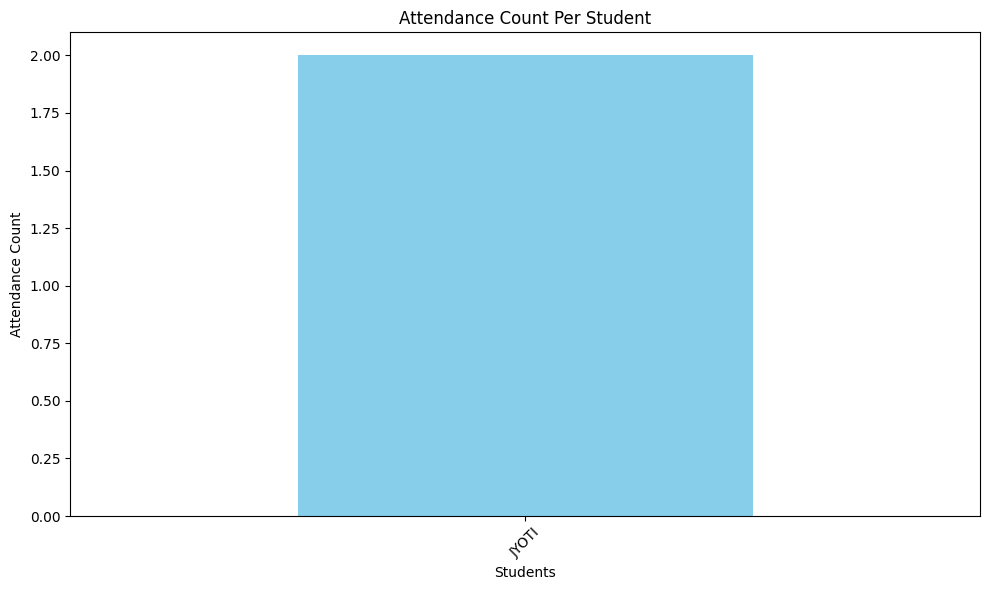

In [18]:
# ================== REAL-TIME RECOGNITION ==================
# Threshold for cosine similarity (higher = stricter)
MATCH_THRESHOLD = 0.6  # Tune between 0.5 and 0.8 as needed

cap = cv2.VideoCapture(0, cv2.CAP_DSHOW)  # CAP_DSHOW for Windows stability

if not cap.isOpened():
    print("Error: Could not open webcam.")
else:
    print("[INFO] Webcam opened.")

with mp_face_mesh.FaceMesh(
    static_image_mode=False,
    max_num_faces=5,
    refine_landmarks=False,
    min_detection_confidence=0.5,
    min_tracking_confidence=0.5
) as face_mesh:

    while True:
        success, img = cap.read()
        if not success:
            print("Error: Failed to capture image")
            break

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, _ = img.shape

        results = face_mesh.process(img_rgb)

        if results.multi_face_landmarks:
            for face_landmarks in results.multi_face_landmarks:
                embedding = landmarks_to_embedding(face_landmarks)

                # Cosine similarity with known encodings
                sims = encodeListKnown @ embedding  # (N,)
                best_idx = int(np.argmax(sims))
                best_sim = float(sims[best_idx])

                # Decide if it's a known face
                if best_sim >= MATCH_THRESHOLD:
                    name = classNames[best_idx].upper()
                    color = (0, 255, 0)  # green
                else:
                    name = "UNKNOWN"
                    color = (0, 0, 255)  # red

                # Bounding box from landmarks
                xs = [lm.x for lm in face_landmarks.landmark]
                ys = [lm.y for lm in face_landmarks.landmark]
                x1 = int(min(xs) * w)
                y1 = int(min(ys) * h)
                x2 = int(max(xs) * w)
                y2 = int(max(ys) * h)

                cv2.rectangle(img, (x1, y1), (x2, y2), color, 2)
                cv2.putText(img, f"{name} ({best_sim:.2f})", (x1, y1 - 10),
                            cv2.FONT_HERSHEY_SIMPLEX, 0.7, color, 2)

                if name != "UNKNOWN":
                    markAttendance(name)

        cv2.imshow('Webcam Attendance (Press q to quit)', img)

        if cv2.waitKey(1) & 0xFF == ord('q'):
            break

cap.release()
cv2.destroyAllWindows()

# ================== PLOT ATTENDANCE ==================
plotAttendance()